---
title: "L7-03 · Quantum kernels and data access"
short_title: "Quantum kernels and data access"
subtitle: "A quantum kernel is an inner product of embedded states, estimated entry by entry from shots; whether it helps depends on how the embedding's geometry differs from strong classical kernels on the given data, and on the cost of estimating roughly $M^2/2$ noisy entries, not on how hard one entry is to compute."
description: "Define a quantum kernel, prove it is positive semidefinite, and evaluate a kernel-method claim with its complete cost: data encoding, shots per Gram entry, number of entries, concentration, and the comparison with classical learners trained on the same data."
tags: [level-7, coursebook]
---

(lesson-l7-03)=

:::{div}
:class: qcai-meta
![Level 7 icon](../../_static/icons/qicon-level-7.svg) **Level 7 · Doctoral & postdoctoral** · about 120 minutes  
**Big idea.** A quantum kernel is an inner product of embedded states, estimated entry by entry from shots; whether it helps depends on how the embedding's geometry differs from strong classical kernels on the given data, and on the cost of estimating roughly $M^2/2$ noisy entries, not on how hard one entry is to compute.  
**Before this lesson.** [L7-01](#lesson-l7-01), [L5-04](#lesson-l5-04)  
**Lab.** [Qubits and the Bloch sphere](../../labs/05-qubit-bloch.ipynb)
:::

## What you will be able to do

- Define a feature map and its kernel $k(x, x') = |\langle\phi(x)|\phi(x')\rangle|^2$, prove that every Gram matrix it produces is positive semidefinite, and compute its rank for small examples.
- Derive the variance of the compute-uncompute and SWAP-test estimators, and use Hoeffding's inequality with a union bound to count the shots needed for a whole Gram matrix.
- Prove that typical kernel values of a product feature map are $2^{-n}$ and explain why exponentially small entries cannot be resolved with polynomially many shots.
- State the geometric-difference test of Huang and coauthors precisely, prove $s_C \le g^2 s_Q$, and use it to judge whether a claimed quantum kernel advantage is possible on given data.

## Why this matters

A paper reports that a quantum kernel classifier on 20 qubits beats a classical support vector machine, and that each kernel entry is classically hard to compute. Three questions decide whether that is evidence of a quantum advantage. How many shots did the Gram matrix cost, and was its accuracy enough for the reported test error? Were the kernel values distinguishable from each other at all, or did they all concentrate near zero? And was the classical baseline the best classical learner trained on the same data, or a weak default?

Each question has a precise answer. A kernel matrix on $M$ training points has $M(M-1)/2$ independent entries, each a Bernoulli estimate. Embeddings into large Hilbert spaces make typical entries exponentially small. And Huang and coauthors showed that a classical learner with data has a prediction-error bound as good as a quantum kernel's, up to a computable geometric factor, so it is competitive whenever that factor is small, even when the quantum kernel is hard to evaluate classically [@advantage]. This lesson builds those three tools, starting from a kernel so simple that every number can be checked by hand.

:::{dropdown} Key terms

**Feature map**
: A map $x \mapsto \rho(x) = |\phi(x)\rangle\langle\phi(x)|$ from inputs to quantum states, implemented by a data-dependent circuit.

**Quantum kernel**
: $k(x, x') = |\langle\phi(x)|\phi(x')\rangle|^2 = \operatorname{Tr}[\rho(x)\rho(x')]$, the similarity used by a classical kernel method [@kernels; @advantage].

**Gram matrix**
: The $M \times M$ matrix $K_{ij} = k(x_i, x_j)$ on the training inputs; a valid kernel gives a positive semidefinite $K$.

**Compute-uncompute estimator**
: Prepare $U(x')^\dagger U(x)|0\rangle$ and record how often the all-zero outcome occurs; the frequency estimates $k(x, x')$.

**Geometric difference**
: $g(K^1\|K^2) = \sqrt{\|\sqrt{K^2}(K^1)^{-1}\sqrt{K^2}\|_\infty}$ for kernels normalized to $\operatorname{Tr} K = M$; it bounds how much worse one kernel's model complexity can be than another's [@advantage].

**Data access model**
: The stated way inputs reach the computer (classical records loaded by circuits, quantum states from an experiment, or an assumed memory oracle), with its cost.

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l7_03 as _lessonfigs

## Feature maps and the kernel trick

:::{prf:definition} Feature map and quantum kernel
:label: def-l7-03-kernel
A **feature map** is a family of $n$-qubit circuits $U(x)$, one per input $x$, with $|\phi(x)\rangle = U(x)|0\rangle^{\otimes n}$ and $\rho(x) = |\phi(x)\rangle\langle\phi(x)|$. Its **quantum kernel** is $k(x, x') = |\langle\phi(x)|\phi(x')\rangle|^2 = \operatorname{Tr}[\rho(x)\rho(x')]$. A kernel method (support vector machine, kernel ridge regression) then learns $h(x) = \sum_i \alpha_i k(x_i, x)$ from the Gram matrix alone [@mml; @kernels].
:::

:::{prf:proposition} Quantum kernels are positive semidefinite
:label: prop-l7-03-psd
For any inputs $x_1, \dots, x_M$, the Gram matrix $K_{ij} = \operatorname{Tr}[\rho(x_i)\rho(x_j)]$ is real, symmetric and positive semidefinite, with $K_{ii} = 1$ and $\operatorname{rank} K \le 4^n$.
:::

:::{prf:proof}
Hermitian $d \times d$ matrices form a real vector space of dimension $d^2$ with inner product $\langle A, B\rangle = \operatorname{Tr}(AB)$. So $K_{ij} = \langle\rho_i, \rho_j\rangle$ is the Gram matrix of the vectors $\rho_i$, and for real $c$, $c^{\mathsf T} K c = \|\sum_i c_i\rho_i\|^2 \ge 0$. Pure states give $K_{ii} = \operatorname{Tr}\rho_i^2 = 1$. The rank of a Gram matrix is the dimension of the span of its vectors, at most $d^2 = 4^n$.
:::

The smallest example is the one the whole lesson checks by hand: $|\phi(x)\rangle = R_Y(x)|0\rangle = \cos\tfrac{x}{2}|0\rangle + \sin\tfrac{x}{2}|1\rangle$. Then $\langle\phi(x)|\phi(x')\rangle = \cos\tfrac{x}{2}\cos\tfrac{x'}{2} + \sin\tfrac{x}{2}\sin\tfrac{x'}{2} = \cos\tfrac{x - x'}{2}$, so

$$
k(x, x') = \cos^2\tfrac{x - x'}{2} = \tfrac{1}{2}(1 + \vec r\cdot\vec r'), \qquad \vec r = (\sin x, 0, \cos x)
$$ (eq-l7-03-ry)

where $\vec r$ is the Bloch vector; the second form, $\operatorname{Tr}(\rho\rho') = \tfrac{1}{2}(1 + \vec r\cdot\vec r')$, holds for any two qubit states. For $x = 0$, $x' = \pi/2$ the kernel is $\tfrac{1}{2}$; for $x = \pi/3$, $x' = \pi$ it is $\cos^2(\pi/3) = \tfrac{1}{4}$. Since $\rho(x) = \tfrac{1}{2}(I + \sin x\, X + \cos x\, Z)$ lies in the span of $I, X, Z$, every Gram matrix of this kernel has rank at most 3, however many inputs there are. This kernel is computed classically by one cosine; running it on a quantum device gives no computational advantage, which is why it is a good test case.

:::{figure} ../../_static/animations/l7_03_feature_map.mp4
:alt: A number line of inputs below a Bloch sphere; two inputs become two arrows on a great circle, and a live readout shows the kernel value as the second input moves.
:width: 100%

The feature map $R_Y(x)|0\rangle$ wraps the input line once around a great circle of the Bloch sphere. The kernel is the squared overlap of two arrows, $\cos^2\tfrac{x - x'}{2}$.
:::

:::{dropdown} What the animation shows
A number line from $0$ to $2\pi$ carries two markers, $x$ (violet) and $x'$ (amber). Above it, a Bloch sphere shows the matching states $R_Y(x)|0\rangle$ and $R_Y(x')|0\rangle$ as arrows in the $xz$ great circle. The formula $k(x, x') = |\langle\phi(x)|\phi(x')\rangle|^2 = \cos^2\tfrac{x - x'}{2} = \tfrac{1}{2}(1 + \vec r\cdot\vec r')$ is written, and a live readout starts at $k = 0.500$ for $x = 0$, $x' = \pi/2$. As $x'$ moves to $\pi$ the arrows become opposite and $k$ falls to 0 (orthogonal states). As $x'$ continues to $2\pi$ the arrow returns to $|0\rangle$ and $k$ returns to 1. Finally $x = \pi/3$ and $x' = \pi$ give $k = 0.250$, and the camera turns around the sphere.
:::

:::{prf:remark} What the quantum device contributes
In a quantum kernel method the device only estimates Gram entries; training and prediction are classical convex optimization over $\alpha$ [@kernels]. Prediction on a new input $x$ needs $k(x_i, x)$ for every training point with $\alpha_i \ne 0$, so test-time cost also scales with $M$ times the shots per entry. The circuit supplies a similarity measure; it does not supply a causal interpretation of the data or of the learned weights.
:::

## Every entry is an estimate

:::{prf:proposition} Two estimators of one entry
:label: prop-l7-03-estimators
(a) **Compute-uncompute.** Prepare $U(x')^\dagger U(x)|0\rangle^{\otimes n}$ and measure all qubits. The all-zero outcome has probability $|\langle 0|U(x')^\dagger U(x)|0\rangle|^2 = k(x, x')$, so the frequency $\hat k$ in $N$ shots is unbiased with $\operatorname{Var}\hat k = k(1 - k)/N \le 1/(4N)$. It uses $n$ qubits and twice the feature-map depth. (b) **SWAP test.** Prepare $|\phi(x)\rangle|\phi(x')\rangle$ and an ancilla, apply the SWAP test; the ancilla reads 0 with probability $\tfrac{1}{2}(1 + k)$, and $\hat k = 2\hat p_0 - 1$ has $\operatorname{Var}\hat k = (1 - k^2)/N$. It uses $2n + 1$ qubits.
:::

:::{prf:proof}
(a) The number of all-zero outcomes is binomial with parameters $N$ and $k$, so the frequency has mean $k$ and variance $k(1 - k)/N$, maximized at $k = \tfrac{1}{2}$. (b) The ancilla outcome is binomial with $p_0 = \tfrac{1}{2}(1 + k)$; $\operatorname{Var}(2\hat p_0 - 1) = 4p_0(1 - p_0)/N = 4\cdot\tfrac{1 + k}{2}\cdot\tfrac{1 - k}{2}/N = (1 - k^2)/N$. For small $k$ the SWAP test variance is close to $1/N$ while compute-uncompute gives about $k/N$, a large difference exactly in the regime of the next section.
:::

:::{prf:theorem} Shots for a whole Gram matrix
:label: thm-l7-03-hoeffding
Estimate each of the $E = M(M-1)/2$ off-diagonal entries by compute-uncompute with $N$ independent shots, where $N$ satisfies [](#eq-l7-03-shots). Then with probability at least $1 - \delta$ every entry satisfies $|\hat K_{ij} - K_{ij}| < \epsilon$, and $\|\hat K - K\|_2 < M\epsilon$.
:::

$$
N \ge \frac{1}{2\epsilon^2}\ln\frac{2E}{\delta} = \frac{1}{2\epsilon^2}\ln\frac{M(M-1)}{\delta}
$$ (eq-l7-03-shots)

:::{prf:proof}
Each shot outcome lies in $\{0, 1\}$, so Hoeffding's inequality [@hoeffding1963] gives $P(|\hat K_{ij} - K_{ij}| \ge \epsilon) \le 2e^{-2N\epsilon^2}$. The union bound over $E$ entries gives failure probability at most $2Ee^{-2N\epsilon^2}$, which is at most $\delta$ under [](#eq-l7-03-shots). For the spectral norm, $\|A\|_2 \le \|A\|_F$ and $\|A\|_F^2 = \sum_{i \ne j} A_{ij}^2 < M^2\epsilon^2$. (The constant differs from the $[-1, 1]$ version in [L7-06](#lesson-l7-06) because the outcomes here lie in $[0, 1]$.)
:::

For $M = 100$, $\epsilon = 0.01$ and $\delta = 0.05$: $E = 4950$, $N \ge \ln(198000)/(2\times 10^{-4}) \approx 60980.1$, so 60981 shots per entry and $3.02\times 10^8$ shots in total, before any test point is predicted. Entrywise error $0.01$ only guarantees spectral error below $M\epsilon = 1$, which can be comparable to the smallest eigenvalues the learner relies on; a spectral target $\eta$ through this route needs $\epsilon = \eta/M$, so the total shot count grows like $M^4\log M/\eta^2$.

:::{figure} ../../_static/animations/l7_03_gram_shots.mp4
:alt: An 8 by 8 grid of colored squares showing a Gram matrix; its entries become noisy estimates, with a readout of the total shots and the smallest eigenvalue, which is negative.
:width: 100%

The $8\times 8$ Gram matrix of $R_Y$ features at $x_i = 2\pi i/8$ has eigenvalues $4, 2, 2$ and five zeros. Its shot-noise estimates cost $28 N$ shots and are not positive semidefinite.
:::

:::{dropdown} What the animation shows
The exact Gram matrix $K_{ij} = \cos^2\tfrac{x_i - x_j}{2}$ with $x_i = 2\pi i/8$ is drawn as an $8\times 8$ grid shaded from white (0) to violet (1). A panel lists its eigenvalues 4, 2, 2, 0, 0, 0, 0, 0: rank 3, positive semidefinite. The panel changes to the compute-uncompute estimator, $\hat K_{ij}$ equal to the frequency of the all-zero outcome, and the count of 28 entries times $N$ shots, $28 N$ in total. The grid is then replaced by estimates with $N = 10$ (280 shots, smallest eigenvalue $-0.266$), $N = 100$ (2800 shots, $-0.111$), $N = 1000$ (28000 shots, $-0.040$) and $N = 10000$ (280000 shots, $-0.013$). The red readout and closing line mark that the estimate has a negative eigenvalue, so it is not a valid kernel matrix.
:::


In [2]:
_show(_lessonfigs.gram_explorer())

**Explore.** Change the shots per entry. Left: the estimated Gram matrix (frequencies, so every entry is at least 0). Right: its eigenvalues next to the exact ones, $4, 2, 2$ and five zeros. The title reports the smallest eigenvalue.

:::{dropdown} What the figure shows
The first panel is a heatmap of the estimated $8\times 8$ Gram matrix of the $R_Y$ kernel at equally spaced inputs. The second panel shows the eight eigenvalues of the exact matrix (gray bars: 4, 2, 2, then zeros) beside those of the estimate (violet bars). With 10 shots per entry the estimate has clearly negative eigenvalues (the smallest is $-0.266$); as the slider moves to $10^5$ shots the violet bars approach the gray ones, but the zero eigenvalues are only approached, with small negative values remaining.
:::

The $R_Y$ kernel end to end: exact Gram matrix, its rank, the Hilbert-Schmidt Gram identity of the proposition, a shot-noise estimate that loses positive semidefiniteness, the two estimators' variances, and the shot count of [](#eq-l7-03-shots) for growing training sets.


In [3]:
import math
import numpy as np
from qcai import science as s

def phi(x):                                   # feature map |phi(x)> = RY(x)|0>
    return s.ry(x) @ np.array([1, 0], complex)

def k_exact(x, z):
    return abs(np.vdot(phi(x), phi(z))) ** 2

print("k(0, pi/2) =", round(k_exact(0, math.pi / 2), 6), "  k(pi/3, pi) =", round(k_exact(math.pi / 3, math.pi), 6))

M = 8
xs = 2 * math.pi * np.arange(M) / M
K = np.array([[k_exact(a, b) for b in xs] for a in xs])
print("eigenvalues:", np.round(np.linalg.eigvalsh(K)[::-1], 6) + 0.0, " rank:", np.linalg.matrix_rank(K, tol=1e-9))
# K is a Hilbert-Schmidt Gram matrix: K_ij = Tr(rho_i rho_j) = <vec rho_i, vec rho_j>
R = np.array([s.dm(phi(a)).reshape(-1) for a in xs])
assert np.allclose(K, (R.conj() @ R.T).real)

# shot-noise estimate of all 28 off-diagonal entries with the compute-uncompute circuit
rng = np.random.default_rng(7)
N = 1000
iu = np.triu_indices(M, 1)
K_hat = np.eye(M)
v = rng.binomial(N, K[iu]) / N
K_hat[iu], K_hat[(iu[1], iu[0])] = v, v
lam = np.linalg.eigvalsh(K_hat)
print(f"N = {N}: total shots {len(v) * N}, max entry error {np.abs(K_hat - K).max():.4f}, "
      f"smallest eigenvalue {lam.min():+.4f}, spectral error {np.linalg.norm(K_hat - K, 2):.4f}")
assert lam.min() < 0                          # the estimate is not positive semidefinite

# variance of one entry (k = 1/2): compute-uncompute k(1-k)/N against the SWAP test (1-k^2)/N
k, reps = K[0, 2], 20000
cu = rng.binomial(N, k, size=reps) / N
sw = 2 * rng.binomial(N, (1 + k) / 2, size=reps) / N - 1
print(f"k = {k:.2f}: compute-uncompute var x N = {cu.var() * N:.3f} (theory {k * (1 - k):.3f}); "
      f"SWAP var x N = {sw.var() * N:.3f} (theory {1 - k * k:.3f})")

# Hoeffding with a union bound over all off-diagonal entries
def shots_per_entry(m, eps, delta):
    pairs = m * (m - 1) // 2
    return pairs, math.ceil(math.log(2 * pairs / delta) / (2 * eps ** 2))

for m in (10, 100, 1000):
    pairs, n = shots_per_entry(m, 0.01, 0.05)
    print(f"M = {m:5d}: {pairs:7d} entries x {n} shots = {pairs * n:.3e} shots for max error 0.01 w.p. 0.95")

k(0, pi/2) = 0.5   k(pi/3, pi) = 0.25
eigenvalues: [4. 2. 2. 0. 0. 0. 0. 0.]  rank: 3
N = 1000: total shots 28000, max entry error 0.0204, smallest eigenvalue -0.0240, spectral error 0.0478
k = 0.50: compute-uncompute var x N = 0.255 (theory 0.250); SWAP var x N = 0.743 (theory 0.750)
M =    10:      45 entries x 37478 shots = 1.687e+06 shots for max error 0.01 w.p. 0.95
M =   100:    4950 entries x 60981 shots = 3.019e+08 shots for max error 0.01 w.p. 0.95
M =  1000:  499500 entries x 84052 shots = 4.198e+10 shots for max error 0.01 w.p. 0.95


:::{caution} Repairing an indefinite estimate
Common fixes project $\hat K$ onto the positive semidefinite cone (clip negative eigenvalues) or add a ridge $\lambda I$. Both are legitimate, but they are part of the method and must be reported with the shot count, because they change the effective kernel the learner uses.
:::

## Large feature spaces and concentration

Embedding into an exponentially large Hilbert space is often presented as the source of power. The same size can make kernel values uninformative. Two exact calculations show how.

:::{prf:proposition} Product feature map
:label: prop-l7-03-product
Let $|\phi(x)\rangle = \bigotimes_{j=1}^n R_Y(x_j)|0\rangle$ with $x, x'$ having independent coordinates uniform on $[0, 2\pi)$. Then $k(x, x') = \prod_j \cos^2\tfrac{x_j - x'_j}{2}$, $E\,k = 2^{-n}$, and $\operatorname{Var} k = (3/8)^n - 4^{-n}$.
:::

:::{prf:proof}
Overlaps of product states factorize: $\langle a \otimes b|c \otimes d\rangle = \langle a|c\rangle\langle b|d\rangle$, which gives the product. The differences $u_j = x_j - x'_j$ taken modulo $2\pi$ are independent and uniform, so $E\cos^2\tfrac{u}{2} = E\tfrac{1}{2}(1 + \cos u) = \tfrac{1}{2}$ and $E\cos^4\tfrac{u}{2} = E\tfrac{1}{4}(1 + \cos u)^2 = \tfrac{1}{4}(1 + \tfrac{1}{2}) = \tfrac{3}{8}$. Independence turns the means of the product into products of means.
:::

:::{prf:proposition} Haar-random states
:label: prop-l7-03-haar
If $|\psi\rangle$ is distributed uniformly (Haar) on unit vectors of $\mathbb{C}^D$, then for any fixed unit vector $|\phi\rangle$, $E|\langle\phi|\psi\rangle|^2 = 1/D$.
:::

:::{prf:proof}
$E|\langle\phi|\psi\rangle|^2 = \langle\phi|\,E[|\psi\rangle\langle\psi|]\,|\phi\rangle$. The operator $E[|\psi\rangle\langle\psi|]$ commutes with every unitary, because the distribution is unitarily invariant, so it is a multiple of $I$; its trace is 1, so it equals $I/D$.
:::

:::{figure} ../../_static/animations/l7_03_concentration.mp4
:alt: Histograms of kernel values for random input pairs collapse toward zero as the number of qubits grows; then a log-scale plot shows the typical kernel value falling below the shot noise of 1000 shots near ten qubits.
:width: 100%

For the product map the typical off-diagonal value is $2^{-n}$. With 1000 shots per entry, the typical entry drops below its own shot noise at $n = \log_2 1001 \approx 9.97$.
:::

:::{dropdown} What the animation shows
A histogram of $k(x, x')$ for 3000 random input pairs of the product map $\bigotimes_j R_Y(x_j)|0\rangle$ is shown for $n = 1, 2, 4, 8$ qubits. For one qubit the values spread over $[0, 1]$ with mean $0.5$; with each step the mass moves toward 0, and the panel shows $E\,k = 2^{-n}$ ($0.5$, $0.25$, $0.0625$, $0.0039$) beside the sample mean. In the second part a log-scale plot against $n$ shows the line $E\,k = 2^{-n}$ and the shot-noise standard deviation $\sqrt{k(1 - k)/N}$ at $k = 2^{-n}$ for $N = 1000$. The two curves cross where $k = 1/(N + 1)$, at $n = \log_2 1001 \approx 9.97$, marked by a red dashed line: beyond it the typical entry is smaller than its own shot noise.
:::


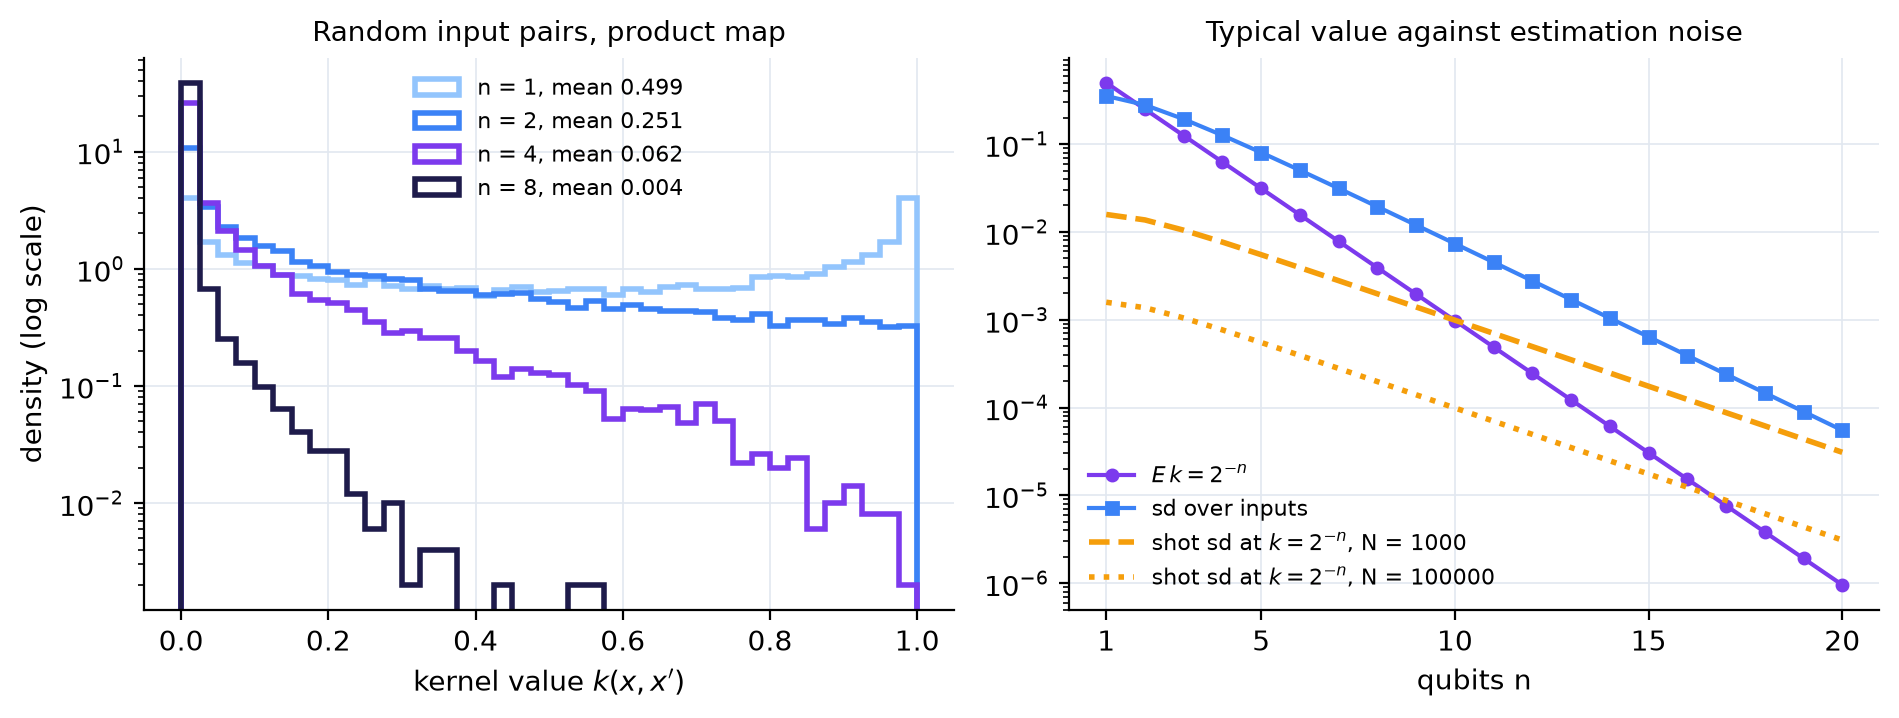

In [4]:
_show_mpl(_lessonfigs.concentration())

*Left: kernel-value distributions of the product map for $n = 1, 2, 4, 8$ (log density). Right: mean $2^{-n}$ and spread over inputs, against the compute-uncompute shot noise at $k = 2^{-n}$ for $N = 10^3$ and $10^5$ shots. Resolving the typical entry to fixed relative accuracy needs $N$ proportional to $2^n$.*

The consequence is quantitative. To estimate an entry of size $k$ with relative error $r$ by compute-uncompute, $N \approx (1 - k)/(r^2 k)$ shots are needed, so typical entries of size $2^{-n}$ need about $2^n/r^2$ shots each. With polynomially many shots the estimated off-diagonal entries are mostly zero, $\hat K \approx I$, and a kernel method can then fit the training labels while generalizing poorly. Note also that the product kernel is classically computable in $O(n)$ operations per entry: concentration is a property of the embedding geometry, not evidence of classical hardness. The two propositions are exact special cases of a general phenomenon: Thanasilp and coauthors show that, under conditions they state, quantum kernel values over different inputs concentrate exponentially toward a fixed value, identify expressive embeddings, global measurements, entanglement and hardware noise as sources, and show that with polynomially many measurements the trained model's predictions on unseen inputs become independent of the input data [@thanasilp2024].

Check both propositions by Monte Carlo: mean and spread of the product kernel against $2^{-n}$ and $\sqrt{(3/8)^n - 4^{-n}}$, the shots needed for 10% relative error, and the Haar average $1/D$ for six qubits.


In [5]:
# Product feature map on n qubits: k(x, z) = prod_j cos^2((x_j - z_j)/2) for independent uniform angles.
rng = np.random.default_rng(11)
print(" n   mean k     2^-n      sd k      theory sd   shots for 10% relative error at k = 2^-n")
for n in (1, 2, 4, 8, 12):
    x = rng.uniform(0, 2 * math.pi, size=(200000, n)); z = rng.uniform(0, 2 * math.pi, size=(200000, n))
    kk = np.prod(np.cos((x - z) / 2) ** 2, axis=1)
    sd_th = math.sqrt((3 / 8) ** n - 4.0 ** -n)
    kt = 2.0 ** -n
    print(f"{n:2d}  {kk.mean():.6f}  {kt:.6f}  {kk.std():.6f}  {sd_th:.6f}  {math.ceil((1 - kt) / (0.01 * kt)):>9d}")
    assert abs(kk.mean() - kt) < 5 * kk.std() / math.sqrt(len(kk))

# Haar-random states: E |<phi|psi>|^2 = 1/D
D = 2 ** 6
v = rng.normal(size=(20000, D)) + 1j * rng.normal(size=(20000, D))
v /= np.linalg.norm(v, axis=1, keepdims=True)
ov = np.abs(v[:, 0]) ** 2                     # overlap with the fixed state |0...0>
print(f"Haar, D = {D}: mean overlap {ov.mean():.5f}  vs 1/D = {1 / D:.5f}")

 n   mean k     2^-n      sd k      theory sd   shots for 10% relative error at k = 2^-n
 1  0.499499  0.500000  0.353503  0.353553        100
 2  0.249810  0.250000  0.279315  0.279508        300
 4  0.062769  0.062500  0.126251  0.125973       1500
 8  0.003871  0.003906  0.019147  0.019386      25500
12  0.000244  0.000244  0.002878  0.002770     409500
Haar, D = 64: mean overlap 0.01564  vs 1/D = 0.01562


## The power of data: classical learners with the same data

Huang and coauthors ask the question an advantage claim must answer: given $M$ training examples $(x_i, y_i)$ with labels from a quantum model $y_i = f(x_i) = \operatorname{Tr}[O^U\rho(x_i)]$, can a classical learner predict $f$ as well as the quantum kernel method? Their main-text bound concerns a kernel method trained on the data, with $K$ normalized so that $\operatorname{Tr} K = M$ [@advantage].

:::{prf:definition} Model complexity and geometric difference
:label: def-l7-03-geometric
For a kernel $K$ on the training inputs and labels $y$, the **model complexity** is $s_K = \sum_{i,j}(K^{-1})_{ij}\, y_i y_j = y^{\mathsf T}K^{-1}y$ (regularized versions replace $K$ by a ridge-regularized matrix). For two kernels normalized to trace $M$, the **geometric difference** is $g(K^1\|K^2) = \sqrt{\|\sqrt{K^2}(K^1)^{-1}\sqrt{K^2}\|_\infty}$, with $\|\cdot\|_\infty$ the spectral norm. Write $g_{CQ} = g(K^C\|K^Q)$ for a classical kernel $K^C$ and the quantum kernel $K^Q$.
:::

:::{prf:theorem} Prediction bound and the geometric test (Huang et al., main-text form)
:label: thm-l7-03-huang
There is a kernel-based learner whose output $h$ after training on $M$ independent samples satisfies the simplified bound $E_{x}|h(x) - f(x)| \le c\sqrt{s_K/M}$ for a constant $c > 0$, with $\operatorname{Tr} K = M$ (the appendix version includes regularization and holds with high probability). Moreover $s_C \le g_{CQ}^2\, s_Q$. For the quantum kernel, $s_Q \le \min(d, \operatorname{Tr}(O^2))$ when $\|O\|_\infty \le 1$, where $d = \operatorname{rank} K^Q \le M$ is the effective dimension of the span of the training states [@advantage].
:::

:::{prf:proof}
We prove only the inequality $s_C \le g_{CQ}^2 s_Q$, for invertible kernels (or their regularized versions). Put $v = (K^Q)^{-1/2}y$. Then $s_C = y^{\mathsf T}(K^C)^{-1}y = v^{\mathsf T}\sqrt{K^Q}(K^C)^{-1}\sqrt{K^Q}\,v \le \|\sqrt{K^Q}(K^C)^{-1}\sqrt{K^Q}\|_\infty\,\|v\|^2 = g_{CQ}^2\, y^{\mathsf T}(K^Q)^{-1}y = g_{CQ}^2 s_Q$, using $u^{\mathsf T}Au \le \|A\|_\infty\|u\|^2$ for positive semidefinite $A$. The prediction bound and the dimension bound are proved in the paper's appendices; we use them as stated.
:::

:::{important} How to read the theorem
If $g_{CQ}$ is small (of order 1), the classical kernel's complexity is at most $g_{CQ}^2$ times the quantum one for every possible labeling, so the classical upper bound on prediction error is at most $g_{CQ}$ times the quantum upper bound: no labeling of these inputs can show a large separation in these bounds. If $g_{CQ}$ is large, the authors show that a labeling with $s_C = g_{CQ}^2 s_Q$ exists and give a construction; a separation is then possible for such labels, not guaranteed for the task at hand. And if $d$ (or $\operatorname{Tr}O^2$) is much smaller than $M$, the quantum kernel method learns every such $f$ from these data; if $g_{CQ}$ is also small, a classical learner does too. These are comparisons of upper bounds with an unspecified constant; actual test errors must still be measured. The quantum kernel can be hard to evaluate classically and still fail all three tests [@advantage].
:::

```{mermaid}
graph TD
  A["training inputs x_1..x_M"] --> B["estimate Gram K_Q with shots"]
  B --> C{"g_CQ small vs best classical kernels?"}
  C -->|yes| D["classical ML predicts as well (bound)"]
  C -->|no, near sqrt M| E{"d or Tr O^2 much less than M?"}
  E -->|yes| F["classical ML can learn it from data"]
  E -->|no| G["label-specific test: s_C vs s_Q"]
  G --> H["advantage possible: measure test error"]
```

*The screening order suggested by the power-of-data analysis. Each arrow needs the shot cost of the Gram matrices that feed it.*

A two-qubit feature map of the type used by Havlicek and coauthors [@kernels], 40 random inputs, and Gaussian classical kernels at three widths. The code computes $d = \operatorname{rank}K^Q$, the geometric difference with a small ridge, and checks $s_C \le g^2 s_Q$ for labels $y_i = \operatorname{Tr}[O\rho(x_i)]$ from a random observable with $\|O\| = 1$.


In [6]:
# A two-qubit feature map of the type used by Havlicek et al.: U(x) H H U(x) H H |00>,
# U(x) = exp(i [x1 Z1 + x2 Z2 + (pi - x1)(pi - x2) Z1 Z2]); and a classical Gaussian kernel.
H2 = s.kron(s.H, s.H)
z1 = np.array([1, 1, -1, -1]); z2 = np.array([1, -1, 1, -1])

def phi2(x):
    U = np.diag(np.exp(1j * (x[0] * z1 + x[1] * z2 + (math.pi - x[0]) * (math.pi - x[1]) * z1 * z2)))
    return U @ H2 @ U @ H2 @ np.array([1, 0, 0, 0], complex)

rng = np.random.default_rng(3)
m = 40
X = rng.uniform(0, 2 * math.pi, size=(m, 2))
S = np.array([phi2(x) for x in X])
KQ = np.abs(S.conj() @ S.T) ** 2              # Tr KQ = m, as Huang et al. assume
print("Tr KQ =", round(KQ.trace(), 6), "  d = rank KQ =", np.linalg.matrix_rank(KQ, tol=1e-8), "(at most 16 for two qubits)")

def msqrt(A):
    w, V = np.linalg.eigh(A)
    return V @ np.diag(np.sqrt(np.clip(w, 0, None))) @ V.T

def g_diff(K1, K2):                           # g(K1 || K2) = sqrt(|| sqrt(K2) K1^{-1} sqrt(K2) ||_inf)
    B = msqrt(K2)
    return math.sqrt(np.linalg.eigvalsh(B @ np.linalg.inv(K1) @ B).max())

lam = 1e-3                                    # ridge so that both matrices are invertible
KQr = KQ + lam * np.eye(m)
O = rng.normal(size=(4, 4)) + 1j * rng.normal(size=(4, 4)); O = O + O.conj().T
O = O / np.abs(np.linalg.eigvalsh(O)).max()   # ||O|| = 1
y = np.real(np.einsum("ni,ij,nj->n", S.conj(), O, S))     # labels y_i = Tr(O rho(x_i))
sQ = y @ np.linalg.solve(KQr, y)
for gamma in (0.05, 0.5, 5.0):
    D2 = ((X[:, None, :] - X[None, :, :]) ** 2).sum(-1)
    KCr = np.exp(-gamma * D2) + lam * np.eye(m)
    g = g_diff(KCr, KQr)
    sC = y @ np.linalg.solve(KCr, y)
    print(f"gamma = {gamma:<4}: g_CQ = {g:8.3f}   s_C = {sC:10.2f}   g^2 s_Q = {g * g * sQ:12.2f}")
    assert sC <= g * g * sQ * (1 + 1e-9)       # s_C <= g^2 s_Q holds for every label vector
print(f"s_Q = {sQ:.2f}  (compare with m = {m})")

Tr KQ = 40.0   d = rank KQ = 16 (at most 16 for two qubits)
gamma = 0.05: g_CQ =   55.463   s_C =    2211.19   g^2 s_Q =      5406.12
gamma = 0.5 : g_CQ =   15.006   s_C =     156.40   g^2 s_Q =       395.74
gamma = 5.0 : g_CQ =    3.044   s_C =       4.10   g^2 s_Q =        16.28
s_Q = 1.76  (compare with m = 40)


In this run $d = 16$, the maximum for two qubits, which is less than $M = 40$, and $s_Q \approx 1.8$: by the dimension bound these labels are learnable from modest data. The geometric difference falls from about 55 for a wide Gaussian kernel ($\gamma = 0.05$) to about 3 for $\gamma = 5$, so a single tuned classical width already brings the classical complexity bound within a factor $g^2 \approx 9$ of the quantum one for every labeling. The inequality $s_C \le g^2 s_Q$ is checked for each width. A real study would minimize $g_{CQ}$ over a suite of tuned classical learners, as the authors recommend [@advantage].

:::{prf:remark} Projected kernels
To avoid the near-identity Gram matrices of large Hilbert spaces, the same paper proposes projected quantum kernels that compare reduced states, for example $k^{PQ}(x, x') = \exp(-\gamma\sum_k\|\rho_k(x) - \rho_k(x')\|_F^2)$ with $\rho_k$ the one-qubit reduced states, and reports engineered data sets on which they outperform tested classical learners in simulations up to 30 qubits [@advantage]. That is a numerical result on constructed data, not a general advantage.
:::

## Data access and the complete cost ledger

:::{prf:remark} Loading classical data is not free
Angle encoding uses one rotation per feature, so $p$ features cost $O(p)$ gates and $p$ qubits (or re-uploading layers). Amplitude encoding stores a $p$-dimensional unit vector in $\lceil\log_2 p\rceil$ qubits, but an arbitrary such vector has $2p - 2$ real parameters, and a circuit of $G$ arbitrary one- and two-qubit gates has at most $15G$ continuous parameters, so exact preparation of almost every such vector needs at least $(2p - 2)/15$ gates, that is $\Omega(p)$. A claim that uses amplitude encoding for free is assuming a memory oracle; that assumption belongs in the access model.
:::

:::{prf:algorithm} Cost ledger for a quantum kernel claim
:label: alg-l7-03-ledger
1. **Encoding:** gates and depth of $U(x)$ per input, and how data reach the device.
2. **Training Gram:** $M(M-1)/2$ entries times shots per entry from [](#eq-l7-03-shots) at the accuracy the learner needs; circuit depth $2\times$ encoding for compute-uncompute.
3. **Repair and training:** PSD projection or ridge, then $O(M^3)$ classical optimization.
4. **Prediction:** $M$ kernel entries per test point, with their shots.
5. **Concentration check:** spread of off-diagonal entries against shot noise.
6. **Baselines:** geometric difference and test error against tuned classical kernels and other strong learners on the same data [@advantage].
7. **Report:** accuracy with uncertainty, all six counts, and what was simulated rather than run.
:::

Havlicek and coauthors introduced quantum kernel estimation with a two-qubit feature map whose kernel they conjectured is hard to estimate classically for larger versions of the circuit, and ran it on a superconducting device [@kernels]. Hardness of computing one kernel entry and advantage in learning are different statements: the first concerns a function evaluation without data; the second concerns prediction from data, where classical learners can use the training examples [@advantage]. Both statements can be true, or the first true and the second false.

## Worked example

:::{admonition} Pricing a small quantum kernel experiment
:class: tip

A study uses the $R_Y$ kernel on $M = 50$ training inputs and 20 test inputs, compute-uncompute estimation, and wants every training entry within $\epsilon = 0.02$ with probability at least $0.95$. Count the shots, give the rank of the exact Gram matrix, and say what can be concluded about quantum advantage.

1. Entries: $E = 50\cdot 49/2 = 1225$ off-diagonal training entries (diagonal entries are 1 and need no shots).
2. Shots per entry from [](#eq-l7-03-shots): $N \ge \ln(2\cdot 1225/0.05)/(2\cdot 0.02^2) = \ln(49000)/0.0008 = 10.80/0.0008 \approx 13500$, so $N = 13500$ (the exact value is 13499.5, rounded up).
3. Training shots: $1225\times 13500 \approx 1.65\times 10^7$. Prediction: $20\times 50 = 1000$ more entries; at the same accuracy, with a union bound now over $2225$ entries, $N$ rises to about $14250$, so the test entries alone need about $1.4\times 10^7$ shots.
4. Rank: $\rho(x)$ lies in the span of $I, X, Z$, so $\operatorname{rank} K \le 3 = d$. By the dimension bound, $s_Q \le 3$, so the kernel method learns from few data; and since $k = \cos^2\tfrac{x - x'}{2}$ is one classical cosine, that kernel method is itself a classical learner.

**Result.** About $3\times 10^7$ shots buy a matrix that a laptop computes exactly in microseconds, and $d = 3$ shows the data are classically easy. The experiment can validate an estimation workflow; it cannot support an advantage claim.
:::

## Exercises

**1. (Core)** Compute $k(\pi/3, \pi)$ for the $R_Y$ kernel, and name two costs that must accompany any claimed quantum speedup of a kernel method.

:::{dropdown} Solution
$k = \cos^2\tfrac{\pi/3 - \pi}{2} = \cos^2(-\pi/3) = \tfrac{1}{4}$. Costs: data encoding (gates per input and the access model), and shots per Gram entry times $M(M-1)/2$ entries; also prediction-time entries, classical training, and PSD repair.
:::

**2. (Core)** For one entry with true value $k = 0.1$ and $N = 1000$ shots, compare the standard deviations of the compute-uncompute and SWAP-test estimators.

:::{dropdown} Solution
Compute-uncompute: $\sqrt{0.1\cdot 0.9/1000} = \sqrt{9\times 10^{-5}} \approx 0.0095$. SWAP: $\sqrt{(1 - 0.01)/1000} \approx 0.0315$. The SWAP test is about 3.3 times noisier at this value, and the gap grows as $k \to 0$, like $1/\sqrt{k}$.
:::

**3. (Stretch)** Show that the $8\times 8$ Gram matrix of the $R_Y$ kernel at $x_i = 2\pi i/8$ has eigenvalues $4, 2, 2, 0, 0, 0, 0, 0$.

:::{dropdown} Solution
Write $K_{ij} = \tfrac{1}{2} + \tfrac{1}{2}\cos(x_i - x_j) = \tfrac{1}{2}\mathbf{1}\mathbf{1}^{\mathsf T} + \tfrac{1}{2}(cc^{\mathsf T} + ss^{\mathsf T})$ with $c_i = \cos x_i$, $s_i = \sin x_i$. For equally spaced angles the vectors $\mathbf{1}$, $c$, $s$ are mutually orthogonal with $\|\mathbf{1}\|^2 = 8$ and $\|c\|^2 = \|s\|^2 = 4$ (sums of $\cos^2$ and $\sin^2$ over 8 equally spaced angles). So $K$ has eigenvalue $\tfrac{1}{2}\cdot 8 = 4$ on $\mathbf{1}$, $\tfrac{1}{2}\cdot 4 = 2$ on $c$ and on $s$, and 0 on their orthogonal complement (dimension 5). The trace check: $4 + 2 + 2 = 8 = M$.
:::

**4. (Stretch)** For the product map on $n$ qubits, how many compute-uncompute shots does a typical entry need for 10% relative error at $n = 12$, and how many for all entries of a 100-point Gram matrix?

:::{dropdown} Solution
Typical $k = 2^{-12} = 1/4096$. $N \approx (1 - k)/(0.01k) = 100(4096 - 1) = 409500$ shots per entry. With $4950$ entries: about $2.0\times 10^9$ shots, before any union bound for simultaneous accuracy. The code prints 409500 for $n = 12$.
:::

**5. (Challenge)** Prove that $g(K^1\|K^2) \ge 1$ whenever both kernels are positive definite with trace $M$. Then give an example with $g = 1$ and explain what it means.

:::{dropdown} Solution
Let $A = \sqrt{K^2}(K^1)^{-1}\sqrt{K^2}$, positive definite. Suppose $\|A\|_\infty < 1$; then $A < I$, i.e. $K^2 < K^1$ in the positive semidefinite order (conjugate $A < I$ by $\sqrt{K^2}^{-1}$ to get $(K^1)^{-1} < (K^2)^{-1}$, equivalently $K^2 < K^1$), and taking traces gives $M = \operatorname{Tr}K^2 < \operatorname{Tr}K^1 = M$, a contradiction. So $g \ge 1$. Example: $K^1 = K^2$ gives $A = I$ and $g = 1$: identical geometry, identical model complexity for every labeling, so the bound offers no room for either kernel to beat the other.
:::

**6. (Challenge)** A paper reports a 20-qubit quantum kernel with test accuracy 0.85 against 0.80 for a default Gaussian SVM, using $M = 200$ and 1000 shots per entry, and states that the feature map is hard to simulate. List the checks from this lesson the paper must pass before its result counts as evidence for a learning advantage, with a quantitative criterion for each.

:::{dropdown} Solution
(1) Shot accuracy: with $N = 1000$, entries have standard deviation up to $0.016$; by [](#eq-l7-03-shots), simultaneous accuracy $\epsilon$ over $19900$ entries with $\delta = 0.05$ requires $N \ge \ln(796000)/(2\epsilon^2)$, so 1000 shots give only $\epsilon \approx 0.08$; report the spectral error and the repair used. (2) Concentration: report the spread of off-diagonal entries; if typical entries are of order $1/N = 10^{-3}$ or smaller (for example of order $2^{-20}$), their shot noise is as large as the entries, the estimated Gram matrix is essentially the identity and the accuracy needs another explanation. (3) Geometric difference: compute $g_{CQ}$ against tuned classical kernels (Gaussian widths, polynomial, neural tangent) on the same 200 inputs; if $g_{CQ} = O(1)$ the classical bound is as good. (4) Dimension: report $d = \operatorname{rank}K^Q$; if $d \ll M$ the quantum kernel method learns from these data, and with $g_{CQ} = O(1)$ a classical learner does too. (5) Baselines: tune the classical models; a default SVM is not the best classical learner. (6) Statistics: a 0.05 difference on a finite test set needs a confidence interval (with 200 test points the standard error of each accuracy is about 0.03). (7) Hardness of the feature map is separate evidence about evaluation, not about learning.
:::

## Check your understanding

**1. Why is every quantum-kernel Gram matrix positive semidefinite?**

- **A.** Only when the feature map is hard to simulate
- **B.** Because its diagonal entries equal 1
- **C.** Because all its entries lie between 0 and 1
- **D.** It is a Gram matrix of density operators under the inner product $\operatorname{Tr}(AB)$

:::{dropdown} Show the answer
**D. It is a Gram matrix of density operators under the inner product $\operatorname{Tr}(AB)$**

$K_{ij} = \operatorname{Tr}(\rho_i\rho_j)$, so $c^{\mathsf T}Kc = \|\sum c_i\rho_i\|^2 \ge 0$. Entries in $[0, 1]$ with unit diagonal do not imply positive semidefiniteness, and shot-noise estimates with those properties can have negative eigenvalues.
:::

**2. Huang and coauthors' geometric difference $g_{CQ}$ between a tuned classical kernel and a quantum kernel is about 1 on the training inputs. What follows?**

- **A.** For every labeling, the classical model complexity is at most about that of the quantum kernel, so the classical error bound is as good
- **B.** The quantum kernel has a guaranteed prediction advantage
- **C.** The training labels must be random
- **D.** The quantum kernel is easy to compute classically

:::{dropdown} Show the answer
**A. For every labeling, the classical model complexity is at most about that of the quantum kernel, so the classical error bound is as good**

$s_C \le g_{CQ}^2 s_Q$ for every label vector, so with $g_{CQ} \approx 1$ the classical bound $c\sqrt{s_C/M}$ is no worse. The statement concerns learning from data, not the cost of evaluating the quantum kernel.
:::

**3. For a product feature map on $n$ qubits with uniformly random inputs, how many shots does compute-uncompute need to estimate a typical entry with fixed relative accuracy?**

- **A.** A number growing like $n$
- **B.** A number growing like $2^n$
- **C.** A number growing like $\log n$
- **D.** A constant independent of $n$

:::{dropdown} Show the answer
**B. A number growing like $2^n$**

Typical entries are $2^{-n}$ and the relative error of a Bernoulli frequency is about $\sqrt{(1 - k)/(Nk)}$, so $N$ must grow like $1/k = 2^n$.
:::

**4. What is $\langle a \otimes b|c \otimes d\rangle$ for single-qubit states?** *(Review of [L5-04](#lesson-l5-04))*

- **A.** $\langle a|b\rangle\langle c|d\rangle$
- **B.** $\langle a|c\rangle + \langle b|d\rangle$
- **C.** $\langle a|c\rangle\langle b|d\rangle$
- **D.** $\langle a|d\rangle\langle b|c\rangle$

:::{dropdown} Show the answer
**C. $\langle a|c\rangle\langle b|d\rangle$**

Inner products of product vectors factorize slot by slot. This is why the product feature map's kernel is a product of one-qubit kernels, and why it concentrates.
:::

## Common misconceptions

- **"A quantum kernel that is hard to compute classically gives a learning advantage."** Learning uses data. Huang and coauthors show that a classical kernel trained on the same data has a prediction-error bound at most $g_{CQ}$ times that of the quantum kernel, so when the geometric difference is small the classical learner is competitive, even if each quantum entry is hard to compute [@advantage].
- **"A bigger Hilbert space means a more powerful kernel."** For many embeddings, typical overlaps scale like the inverse dimension (exactly $2^{-n}$ for the product map, $1/D$ for Haar-random states). Then the Gram matrix is close to the identity and entries need exponentially many shots to resolve.
- **"The kernel circuit is shallow, so the method is cheap."** Cost multiplies: about $M^2/2$ entries, each with shots that grow with $\log M$ for simultaneous accuracy, plus prediction entries and data loading. A shallow circuit per entry does not make the ledger short.
- **"A noisy Gram estimate is still a valid kernel."** Shot noise generally destroys positive semidefiniteness, especially when the true matrix has zero eigenvalues; the repair step changes the kernel and must be reported.

:::{caution} Scope and limits
All results are noiseless classical simulations with ideal binomial sampling; device noise adds bias to every entry. The $R_Y$ and product kernels are deliberately classically tractable: they illustrate mechanics and cannot support an advantage claim. The concentration results are for the stated product map with uniform inputs and for Haar-random states; other feature maps and input distributions behave differently and must be checked. The Huang et al. theorem is quoted in its main-text form, with an unspecified constant and trace normalization $\operatorname{Tr}K = M$; it compares upper bounds on prediction error, so a small or large geometric difference is a screening result, not a measured error. We prove only $s_C \le g^2 s_Q$ ourselves.
:::

:::{seealso} Where this leads
The cost ledger here is one instance of the resource accounting in [L7-06](#lesson-l7-06), and the geometric-difference test is the template for the benchmark design of [L7-08](#lesson-l7-08), where a quantum model must be compared with strong classical learners on identical data. Variational models from [L7-02](#lesson-l7-02) use the same feature-map circuits; the encoding determines the frequencies they can represent.
:::

:::{dropdown} For instructors

**Why this lesson.** Quantum kernels are the cleanest setting in which to teach how a quantum-advantage claim in learning is audited: the object is explicit, positive semidefinite by construction, estimated by Bernoulli trials, and comparable to classical kernels through a single matrix quantity [@kernels; @advantage]. The lesson trains students to count resources and to separate hardness of evaluation from advantage in learning.

**Teaching notes.**

- Start from the $R_Y$ kernel and have students derive $\cos^2\tfrac{x - x'}{2}$ and the rank bound 3 before any software; then the code only confirms.
- Use the Gram-matrix animation to provoke the question of why a matrix with entries in $[0, 1]$ and ones on the diagonal can fail to be positive semidefinite; the zero eigenvalues of the exact matrix are the reason.
- Assign the last challenge exercise as a written referee report; it is a realistic research skill and uses every section.
- Stress that the Huang et al. bound is about upper bounds and screening; ask students what measurement would still be needed after the test is passed.

**Assessment.** The stretch exercise on eigenvalues checks linear algebra fluency; the referee-report challenge checks whether students can turn the lesson's propositions into quantitative criteria. The review check confirms the tensor-product rule behind concentration.

**Going further.** Read the appendices of Huang et al. on the prediction-error bound and on constructing labels that saturate $s_C = g^2 s_Q$, and reproduce the geometric difference for a projected kernel on the two-qubit example [@advantage]. Compare with the original quantum kernel estimation experiment [@kernels] and with the encoding analysis of variational models [@encoding].

:::

## References

This lesson draws on [@kernels; @advantage; @mml; @encoding; @hoeffding1963; @thanasilp2024].

**Further reading.**

- [@qml]: Survey of quantum machine learning that frames data-access assumptions and their costs.
- [@vqa]: How kernel-type feature maps appear inside variational algorithms.

**Next:** [L7-04 · Barren plateaus and trainability](#lesson-l7-04)
